# Household Income and Expenditure Analysis

This notebook explores household income, spending, budgets and savings using the uploaded dataset.

## Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from io import BytesIO

up = files.upload()
df = pd.read_csv(list(up.keys())[0])
df.head()

Saving household_consumption_dataset.csv to household_consumption_dataset.csv


,Date,City,Household_Size,Dependents,Category,Subcategory,Expense,Budget,Income,Savings,Status,Payment_Mode
0,07-02-2024,Pune,4,3,Travel,Public Transport,335,931,70057,69722,Under Budget,Cash
1,13-05-2024,Bangalore,5,4,Rent,House Rent,2995,3455,40609,37614,Under Budget,Net Banking
2,12-03-2024,Pune,2,1,Healthcare,Medicines,2897,2905,56230,53333,Under Budget,Net Banking
3,27-06-2024,Bangalore,4,3,Food,Snacks,4553,4967,71668,67115,Under Budget,UPI
4,09-09-2024,Mumbai,3,2,Education,Books,3662,3830,77245,73583,Under Budget,UPI


In [2]:
print("Shape:", df.shape)
print(df.columns)
print(df.info())
print(df.describe(include="all"))

Shape: (12000, 12)
Index(['Date', 'City', 'Household_Size', 'Dependents', 'Category',
       'Subcategory', 'Expense', 'Budget', 'Income', 'Savings', 'Status',
       'Payment_Mode'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Date            12000 non-null  object
 1   City            12000 non-null  object
 2   Household_Size  12000 non-null  int64 
 3   Dependents      12000 non-null  int64 
 4   Category        12000 non-null  object
 5   Subcategory     12000 non-null  object
 6   Expense         12000 non-null  int64 
 7   Budget          12000 non-null  int64 
 8   Income          12000 non-null  int64 
 9   Savings         12000 non-null  int64 
 10  Status          12000 non-null  object
 11  Payment_Mode    12000 non-null  object
dtypes: int64(6), object(6)
memory usage: 1.1+ MB
None
              

## NumPy and basic exploration

In [3]:
income = df["Income"].to_numpy()
expense = df["Expense"].to_numpy()
savings = df["Savings"].to_numpy()

print("Average income:", np.mean(income))
print("Minimum income:", np.min(income))
print("Maximum income:", np.max(income))
print("Average expense:", np.mean(expense))
print("Minimum expense:", np.min(expense))
print("Maximum expense:", np.max(expense))

one_d = np.array([10, 20, 30, 40])
two_d = np.array([[1, 2, 3], [4, 5, 6]])
three_d = np.array([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])

print(one_d[1:3])
print(two_d[:, 1])
print(three_d.shape)
print("Broadcasting:", two_d + np.array([10, 20, 30]))
print("Matrix transpose:\n", two_d.T)
print("Reshaped array:", one_d.reshape(2, 2))
print("Column-wise means:", np.mean(two_d, axis=0))
print("Random sample:", np.random.default_rng(7).integers(1, 10, size=5))

Average income: 60306.71941666667
Minimum income: 20011
Maximum income: 99989
Average expense: 2538.6601666666666
Minimum expense: 100
Maximum expense: 4999
[20 30]
[2 5]
(2, 2, 2)
Broadcasting: [[11 22 33]
 [14 25 36]]
Matrix transpose:
 [[1 4]
 [2 5]
 [3 6]]
Reshaped array: [[10 20]
 [30 40]]
Column-wise means: [2.5 3.5 4.5]
Random sample: [9 6 7 9 6]


## Cleaning and preparation

In [4]:
print("Missing values before cleaning:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")
for col in ["Household_Size", "Dependents", "Expense", "Budget", "Income", "Savings"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["City"] = df["City"].replace({"Bengaluru": "Bangalore"})
df["Category"] = df["Category"].fillna("Unknown")
df["Subcategory"] = df["Subcategory"].fillna("Unknown")
df["Payment_Mode"] = df["Payment_Mode"].fillna("Unknown")
for col in ["Household_Size", "Dependents", "Expense", "Budget", "Income", "Savings"]:
    df[col] = df[col].fillna(df[col].median())

df = df.dropna(subset=["Date"]).copy()
print("Missing values after cleaning:\n", df.isna().sum())
print("Duplicate rows after cleaning:", df.duplicated().sum())
df.head()

Missing values before cleaning:
 Date              0
City              0
Household_Size    0
Dependents        0
Category          0
Subcategory       0
Expense           0
Budget            0
Income            0
Savings           0
Status            0
Payment_Mode      0
dtype: int64
Duplicate rows: 0
Missing values after cleaning:
 Date              0
City              0
Household_Size    0
Dependents        0
Category          0
Subcategory       0
Expense           0
Budget            0
Income            0
Savings           0
Status            0
Payment_Mode      0
dtype: int64
Duplicate rows after cleaning: 0


,Date,City,Household_Size,Dependents,Category,Subcategory,Expense,Budget,Income,Savings,Status,Payment_Mode
0,2024-02-07,Pune,4,3,Travel,Public Transport,335,931,70057,69722,Under Budget,Cash
1,2024-05-13,Bangalore,5,4,Rent,House Rent,2995,3455,40609,37614,Under Budget,Net Banking
2,2024-03-12,Pune,2,1,Healthcare,Medicines,2897,2905,56230,53333,Under Budget,Net Banking
3,2024-06-27,Bangalore,4,3,Food,Snacks,4553,4967,71668,67115,Under Budget,UPI
4,2024-09-09,Mumbai,3,2,Education,Books,3662,3830,77245,73583,Under Budget,UPI


## Transformation and categorization

In [5]:
df["Savings_Rate"] = np.where(df["Income"] > 0, df["Savings"] / df["Income"] * 100, 0)
df["Expense_to_Budget"] = np.where(df["Budget"] > 0, df["Expense"] / df["Budget"] * 100, 0)
df["Income_Group"] = pd.cut(
    df["Income"],
    bins=3,
    labels=["Low income", "Middle income", "High income"]
)
df["Expense_Level"] = pd.cut(
    df["Expense_to_Budget"],
    bins=[-np.inf, 80, 100, np.inf],
    labels=["Below budget", "Near budget", "Over budget"]
)
df = df.rename(columns={"Household_Size": "Family_Size"})
df_sorted = df.sort_values("Income", ascending=False)
df_sorted[["City", "Family_Size", "Income", "Expense", "Savings", "Income_Group"]].head(10)

,City,Family_Size,Income,Expense,Savings,Income_Group
1590,Mumbai,4,99989,784,99205,High income
11766,Pune,2,99978,4378,95600,High income
3014,Hyderabad,1,99972,989,98983,High income
747,Bangalore,2,99956,731,99225,High income
8655,Hyderabad,4,99953,832,99121,High income
5798,Bangalore,3,99950,434,99516,High income
8838,Delhi,3,99944,169,99775,High income
4087,Bangalore,3,99942,3052,96890,High income
5965,Mumbai,5,99936,4573,95363,High income
8257,Hyderabad,3,99929,2632,97297,High income


## Household analysis questions

The supplied Q1–Q5 wording refers to the Titanic dataset (`Age`, `Survived`, `Pclass`, `Sex`, `Embarked`). Those columns are not in this household dataset, so passenger survival calculations cannot be performed from this file. The following five questions use the same analysis methods with the household columns that are actually available.

### Q1. NumPy statistics by household budget status

In [6]:
for status in df["Status"].dropna().unique():
    values = df.loc[df["Status"] == status, "Expense"].to_numpy()
    if len(values):
        print(status)
        print("Average expense:", np.mean(values))
        print("Minimum expense:", np.min(values))
        print("Maximum expense:", np.max(values))
        print()

Under Budget
Average expense: 2540.0504861630516
Minimum expense: 100
Maximum expense: 4999

Over Budget
Average expense: 2535.856460532931
Minimum expense: 100
Maximum expense: 4999



### Q2. Income, expenditure and savings by city and category

In [7]:
city_summary = df.groupby("City").agg(
    Average_Income=("Income", "mean"),
    Average_Expense=("Expense", "mean"),
    Average_Savings=("Savings", "mean"),
    Household_Records=("City", "size")
).round(2)

category_summary = df.groupby("Category").agg(
    Total_Expense=("Expense", "sum"),
    Average_Expense=("Expense", "mean"),
    Average_Budget=("Budget", "mean"),
    Average_Savings=("Savings", "mean")
).round(2)

display(city_summary)
display(category_summary.sort_values("Total_Expense", ascending=False))

,Average_Income,Average_Expense,Average_Savings,Household_Records
City,,,,
Bangalore,60368.88,2553.47,57815.41,2430
Delhi,60629.79,2598.37,58031.42,2333
Hyderabad,61106.94,2525.25,58581.69,2402
Mumbai,59566.61,2493.86,57072.74,2425
Pune,59878.45,2524.37,57354.08,2410


,Total_Expense,Average_Expense,Average_Budget,Average_Savings
Category,,,,
Utilities,3166646,2610.59,2860.21,58815.68
Travel,3147224,2515.77,2750.41,57346.02
Groceries,3136407,2568.72,2822.62,57042.21
Healthcare,3125785,2502.63,2757.35,57587.45
Shopping,3043477,2536.23,2784.62,57106.20
Entertainment,3015222,2491.92,2744.27,58663.49
Rent,3013027,2579.65,2829.42,58019.98
Food,2980963,2528.38,2775.59,58067.30
Insurance,2976232,2515.83,2762.63,57420.16


### Q3. Missing-value treatment

In [8]:
missing_report = df.isna().sum().to_frame("Missing_Values")
display(missing_report)
print("Age and Cabin are not columns in this household dataset.")
print("Household numerical fields were filled with their median and category fields with 'Unknown' where needed.")

,Missing_Values
Date,0
City,0
Family_Size,0
Dependents,0
Category,0
Subcategory,0
Expense,0
Budget,0
Income,0
Savings,0


Age and Cabin are not columns in this household dataset.
Household numerical fields were filled with their median and category fields with 'Unknown' where needed.


### Q4. Group households by city and budget status

In [9]:
city_status = df.groupby(["City", "Status"], observed=False).agg(
    Record_Count=("Status", "size"),
    Mean_Income=("Income", "mean"),
    Mean_Expense=("Expense", "mean"),
    Mean_Savings=("Savings", "mean")
).round(2)

display(city_status)
status_counts = df.groupby(["City", "Status"], observed=False).size().unstack(fill_value=0)
display(status_counts)

Record_Count  Mean_Income  Mean_Expense  Mean_Savings
City      Status                                                             
Bangalore Over Budget            814     59833.29       2556.21      57277.07
          Under Budget          1616     60638.66       2552.09      58086.58
Delhi     Over Budget            766     61483.28       2577.72      58905.55
          Under Budget          1567     60212.58       2608.46      57604.11
Hyderabad Over Budget            812     60185.98       2512.80      57673.17
          Under Budget          1590     61577.27       2531.60      59045.67
Mumbai    Over Budget            789     59110.24       2458.92      56651.32
          Under Budget          1636     59786.70       2510.72      57275.98
Pune      Over Budget            797     60213.58       2574.48      57639.11
          Under Budget          1613     59712.86       2499.61      57213.25

Status,Over Budget,Under Budget
City,,
Bangalore,814,1616
Delhi,766,1567
Hyderabad,812,1590
Mumbai,789,1636
Pune,797,1613


### Q5. Bar plots and heatmap

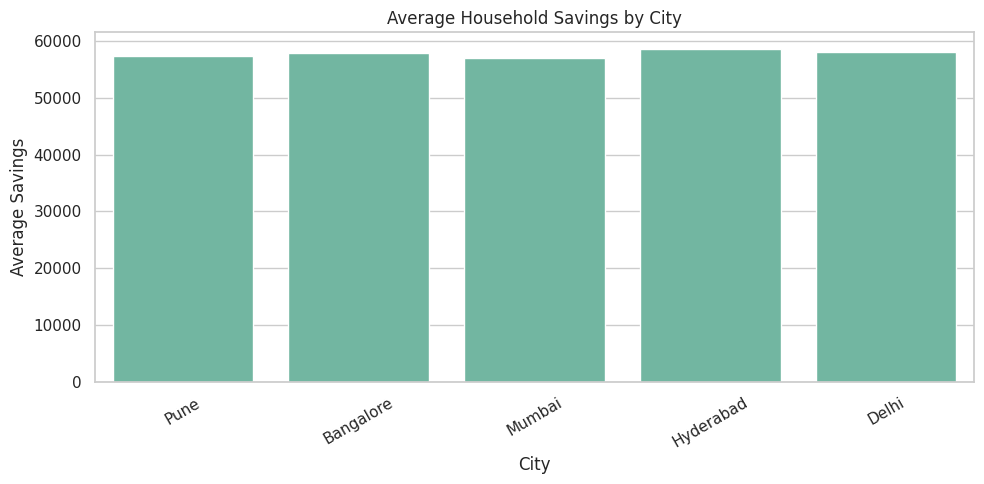

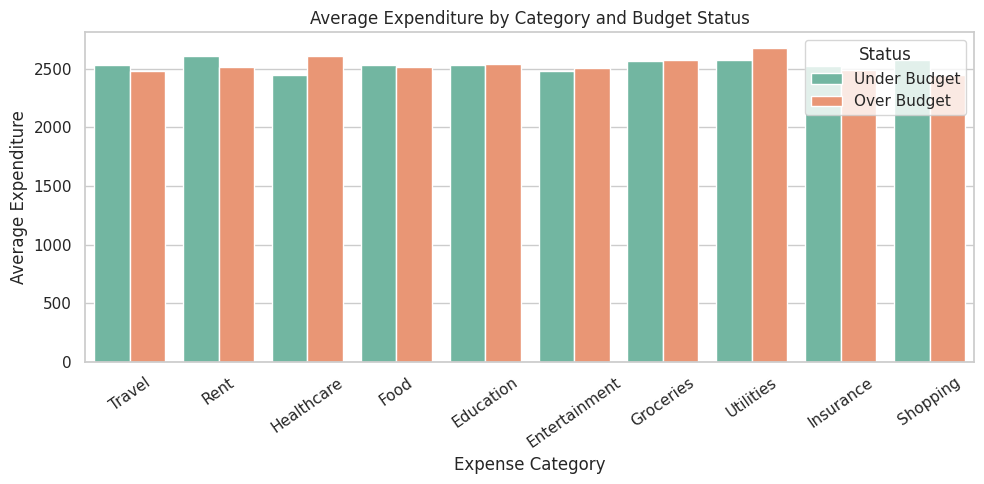

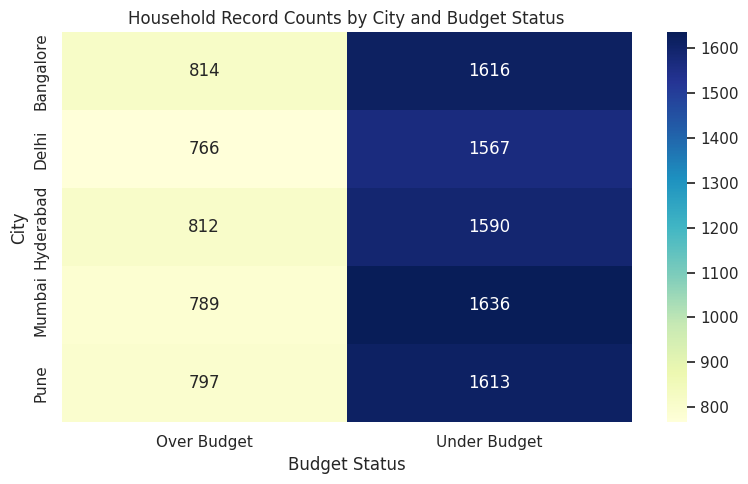

In [10]:
sns.set_theme(style="whitegrid", palette="Set2")

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="City", y="Savings", estimator="mean", errorbar=None)
plt.title("Average Household Savings by City")
plt.xlabel("City")
plt.ylabel("Average Savings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="Category", y="Expense", hue="Status", estimator="mean", errorbar=None)
plt.title("Average Expenditure by Category and Budget Status")
plt.xlabel("Expense Category")
plt.ylabel("Average Expenditure")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(status_counts, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Household Record Counts by City and Budget Status")
plt.xlabel("Budget Status")
plt.ylabel("City")
plt.tight_layout()
plt.show()

## Pandas operations and reshaping

In [11]:
income_series = pd.Series(df["Income"].head(5).to_numpy(), index=df["City"].head(5))
display(income_series)
display(df.loc[:4, ["City", "Category", "Income", "Expense"]])
display(df.iloc[:5, :4])
print("Dataset dimensions:", df.shape)
print("Column names:", df.columns.tolist())

city_category = df.groupby(["City", "Category"]).agg(
    Total_Expense=("Expense", "sum"),
    Average_Income=("Income", "mean")
)
display(city_category.head(10))

city_expense = df.groupby(["City", "Category"])["Expense"].sum().unstack(fill_value=0)
display(city_expense.head())

pivot_table = df.pivot_table(
    index="City", columns="Category", values="Expense",
    aggfunc="mean", fill_value=0
)
display(pivot_table)

stacked = city_expense.stack()
display(stacked.head())

,0
City,
Pune,70057
Bangalore,40609
Pune,56230
Bangalore,71668
Mumbai,77245


,City,Category,Income,Expense
0,Pune,Travel,70057,335
1,Bangalore,Rent,40609,2995
2,Pune,Healthcare,56230,2897
3,Bangalore,Food,71668,4553
4,Mumbai,Education,77245,3662


,Date,City,Family_Size,Dependents
0,2024-02-07,Pune,4,3
1,2024-05-13,Bangalore,5,4
2,2024-03-12,Pune,2,1
3,2024-06-27,Bangalore,4,3
4,2024-09-09,Mumbai,3,2


Dataset dimensions: (12000, 16)
Column names: ['Date', 'City', 'Family_Size', 'Dependents', 'Category', 'Subcategory', 'Expense', 'Budget', 'Income', 'Savings', 'Status', 'Payment_Mode', 'Savings_Rate', 'Expense_to_Budget', 'Income_Group', 'Expense_Level']


Total_Expense  Average_Income
City      Category                                    
Bangalore Education             569091    62551.411255
          Entertainment         565952    61707.160000
          Food                  581941    60808.355932
          Groceries             631275    59469.546512
          Healthcare            636533    59115.733871
          Insurance             664093    61089.254682
          Rent                  578667    60909.232456
          Shopping              659747    59521.392562
          Travel                658238    58447.911647
          Utilities             659390    60375.707317

Category,Education,Entertainment,Food,Groceries,Healthcare,Insurance,Rent,Shopping,Travel,Utilities
City,,,,,,,,,,
Bangalore,569091,565952,581941,631275,636533,664093,578667,659747,658238,659390
Delhi,649793,514133,685129,586776,598622,612061,590283,660027,584916,580257
Hyderabad,552901,660234,586756,580809,691255,559285,569847,550409,678358,635788
Mumbai,562591,660056,563759,685938,572953,546078,654698,575214,609331,617003
Pune,524563,614847,563378,651609,626422,594715,619532,598080,616381,674208


Category,Education,Entertainment,Food,Groceries,Healthcare,Insurance,Rent,Shopping,Travel,Utilities
City,,,,,,,,,,
Bangalore,2463.597403,2515.342222,2465.851695,2446.802326,2566.665323,2487.239700,2538.013158,2726.227273,2643.526104,2680.447154
Delhi,2663.086066,2459.966507,2665.871595,2643.135135,2443.355102,2720.271111,2647.008969,2598.531496,2543.113043,2590.433036
Hyderabad,2403.917391,2510.395437,2496.834043,2492.742489,2579.309701,2565.527523,2662.836449,2479.319820,2503.166052,2563.661290
Mumbai,2616.702326,2578.343750,2409.226496,2618.083969,2377.398340,2374.252174,2557.414062,2396.725000,2447.112450,2549.599174
Pune,2546.422330,2392.400778,2596.211982,2648.817073,2536.121457,2447.386831,2508.226721,2471.404959,2445.956349,2664.853755


City       Category     
Bangalore  Education        569091
           Entertainment    565952
           Food             581941
           Groceries        631275
           Healthcare       636533
dtype: int64

## Combining data

In [12]:
first_part = df.iloc[:len(df)//2].copy()
second_part = df.iloc[len(df)//2:].copy()
combined = pd.concat([first_part, second_part], ignore_index=True)

city_info = df[["City"]].drop_duplicates().copy()
city_info["Region_Group"] = "Other"
city_info.loc[city_info["City"].isin(["Mumbai", "Pune"]), "Region_Group"] = "West"
city_info.loc[city_info["City"].isin(["Bangalore", "Hyderabad"]), "Region_Group"] = "South"

merged = df.merge(city_info, on="City", how="left")
display(combined.head())
display(merged[["City", "Region_Group", "Income", "Expense"]].head())

,Date,City,Family_Size,Dependents,Category,Subcategory,Expense,Budget,Income,Savings,Status,Payment_Mode,Savings_Rate,Expense_to_Budget,Income_Group,Expense_Level
0,2024-02-07,Pune,4,3,Travel,Public Transport,335,931,70057,69722,Under Budget,Cash,99.521818,35.982814,Middle income,Below budget
1,2024-05-13,Bangalore,5,4,Rent,House Rent,2995,3455,40609,37614,Under Budget,Net Banking,92.624788,86.685962,Low income,Near budget
2,2024-03-12,Pune,2,1,Healthcare,Medicines,2897,2905,56230,53333,Under Budget,Net Banking,94.847946,99.724613,Middle income,Near budget
3,2024-06-27,Bangalore,4,3,Food,Snacks,4553,4967,71668,67115,Under Budget,UPI,93.647095,91.664989,Middle income,Near budget
4,2024-09-09,Mumbai,3,2,Education,Books,3662,3830,77245,73583,Under Budget,UPI,95.259240,95.613577,High income,Near budget


,City,Region_Group,Income,Expense
0,Pune,West,70057,335
1,Bangalore,South,40609,2995
2,Pune,West,56230,2897
3,Bangalore,South,71668,4553
4,Mumbai,West,77245,3662


## Time series analysis

,Income,Expense,Savings,Budget
Date,,,,
2024-01-01,59941927,2548380,57393547,2796469
2024-02-01,60162134,2629664,57532470,2884832
2024-03-01,61080137,2620116,58460021,2875730
2024-04-01,56183886,2368905,53814981,2594965
2024-05-01,63897810,2662656,61235154,2938405


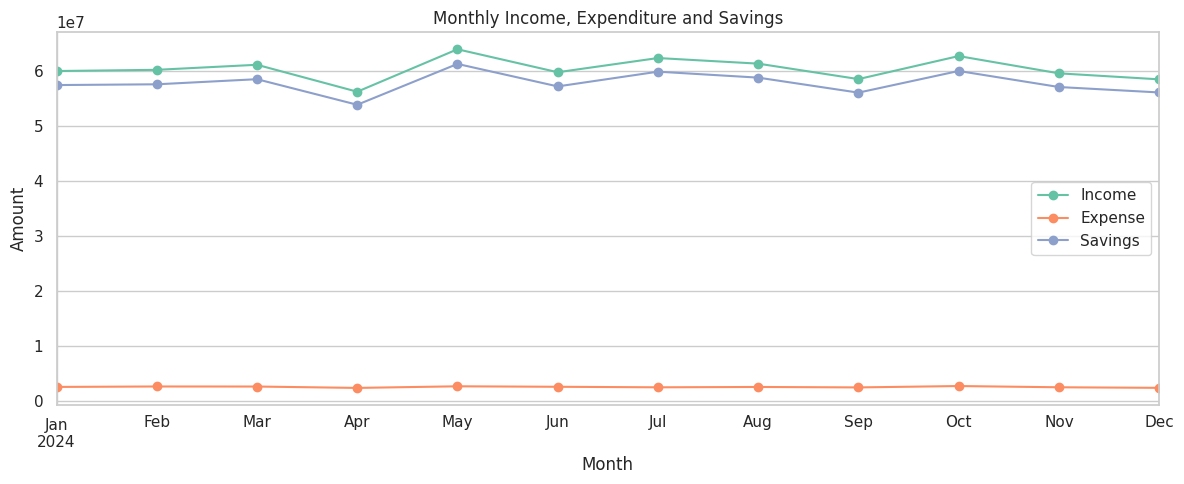

Records from the first quarter:


,Date,City,Family_Size,Dependents,Category,Subcategory,Expense,Budget,Income,Savings,Status,Payment_Mode,Savings_Rate,Expense_to_Budget,Income_Group,Expense_Level
0,2024-02-07,Pune,4,3,Travel,Public Transport,335,931,70057,69722,Under Budget,Cash,99.521818,35.982814,Middle income,Below budget
2,2024-03-12,Pune,2,1,Healthcare,Medicines,2897,2905,56230,53333,Under Budget,Net Banking,94.847946,99.724613,Middle income,Near budget
5,2024-03-09,Pune,1,0,Entertainment,Movies,3149,3402,46103,42954,Under Budget,UPI,93.169642,92.563198,Low income,Near budget
6,2024-03-27,Bangalore,2,1,Groceries,Supermarket,1131,950,23606,22475,Over Budget,Card,95.208845,119.052632,Low income,Over budget
7,2024-01-02,Hyderabad,4,3,Healthcare,Medicines,4512,4221,78072,73560,Over Budget,Card,94.220719,106.894101,High income,Over budget


In [13]:
monthly = df.set_index("Date").sort_index()
monthly_totals = monthly[["Income", "Expense", "Savings", "Budget"]].resample("MS").sum()
display(monthly_totals.head())

monthly_totals[["Income", "Expense", "Savings"]].plot(figsize=(12, 5), marker="o")
plt.title("Monthly Income, Expenditure and Savings")
plt.xlabel("Month")
plt.ylabel("Amount")
plt.legend()
plt.tight_layout()
plt.show()

print("Records from the first quarter:")
display(df[df["Date"].dt.quarter == 1].head())

## Additional visual analysis

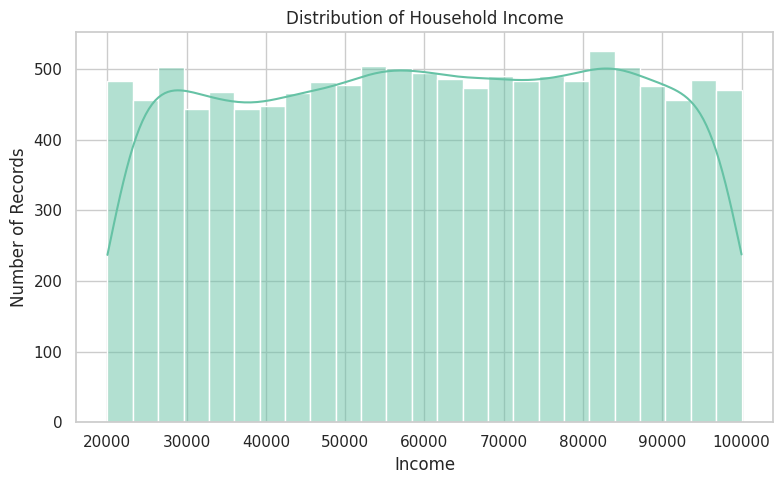

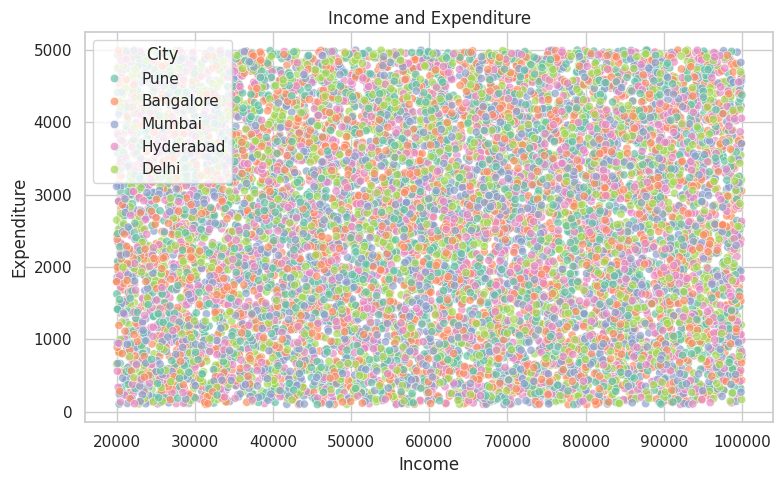

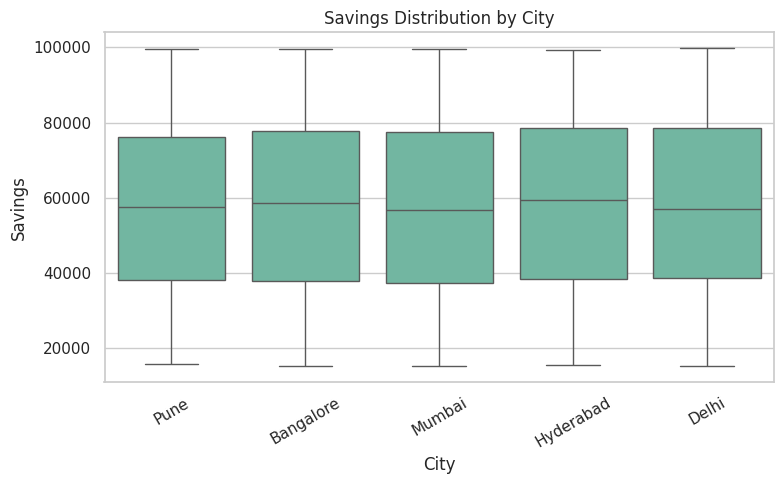

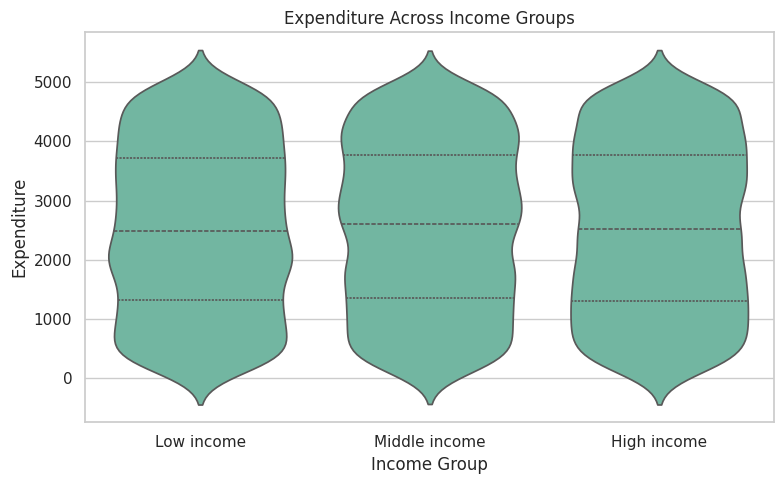

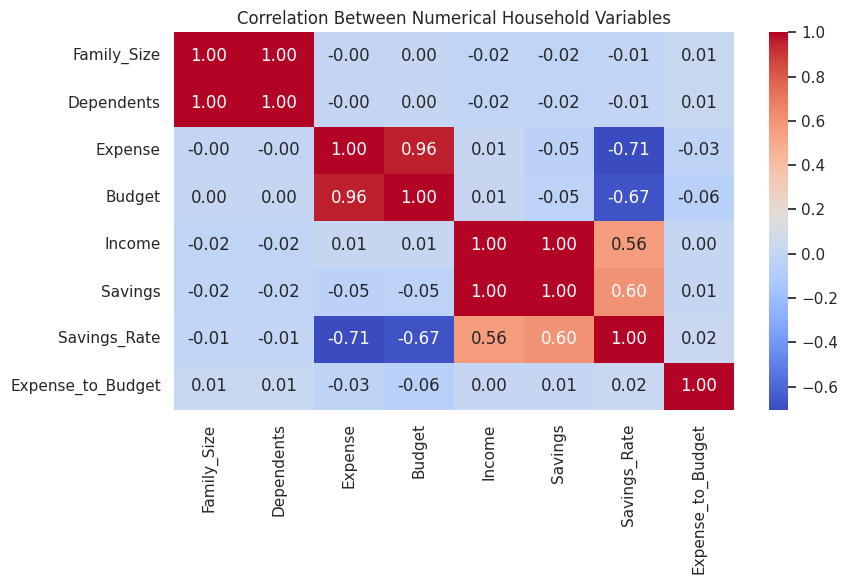

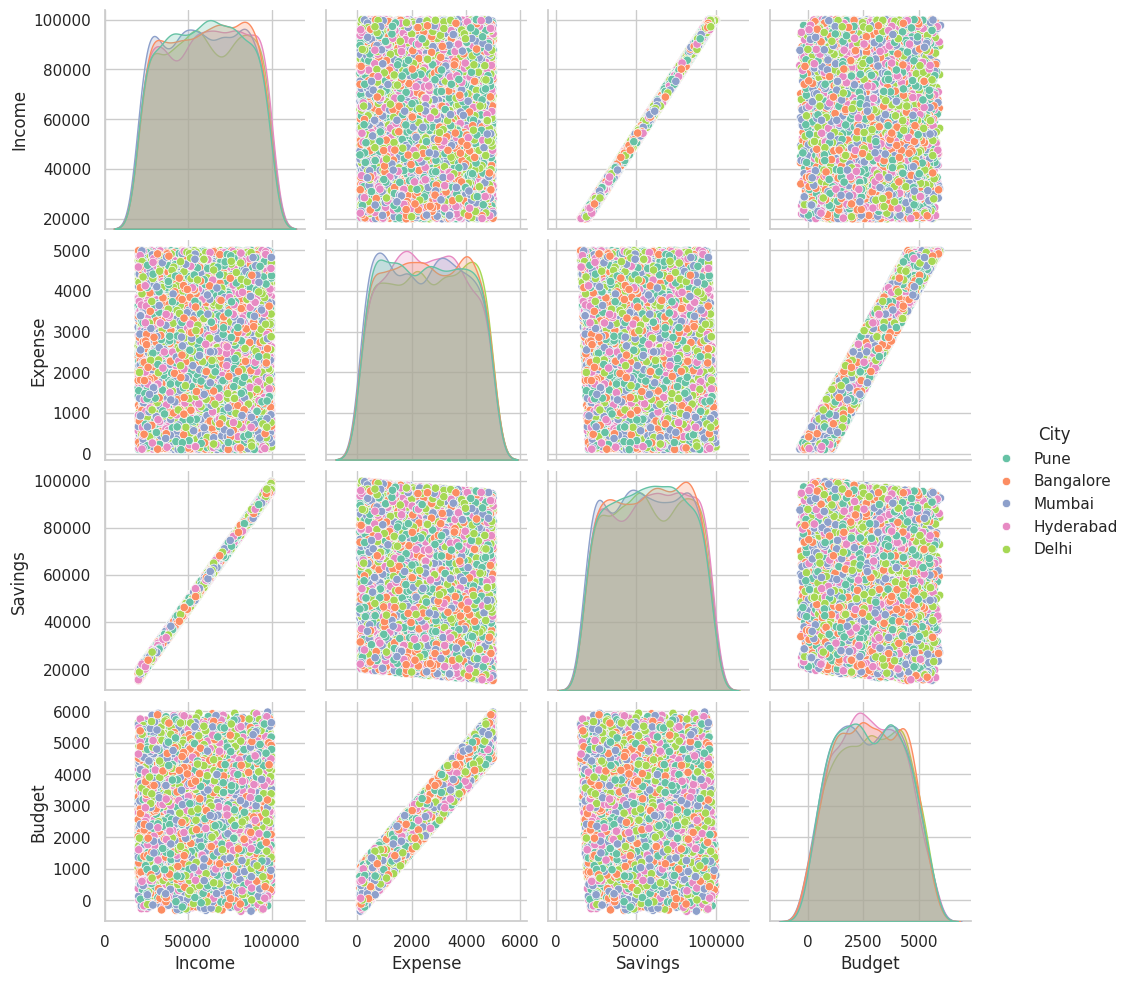

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Income", bins=25, kde=True)
plt.title("Distribution of Household Income")
plt.xlabel("Income")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Income", y="Expense", hue="City", alpha=0.7)
plt.title("Income and Expenditure")
plt.xlabel("Income")
plt.ylabel("Expenditure")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="City", y="Savings")
plt.title("Savings Distribution by City")
plt.xlabel("City")
plt.ylabel("Savings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="Income_Group", y="Expense", inner="quartile")
plt.title("Expenditure Across Income Groups")
plt.xlabel("Income Group")
plt.ylabel("Expenditure")
plt.tight_layout()
plt.show()

numeric = df.select_dtypes(include=np.number)
plt.figure(figsize=(9, 6))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Between Numerical Household Variables")
plt.tight_layout()
plt.show()

sns.pairplot(df[["Income", "Expense", "Savings", "Budget", "City"]], hue="City")
plt.show()

## Conclusion

In [15]:
summary = df.groupby("City").agg(
    Average_Income=("Income", "mean"),
    Average_Expense=("Expense", "mean"),
    Average_Savings=("Savings", "mean")
).round(2)
display(summary)

highest_expense_category = df.groupby("Category")["Expense"].sum().idxmax()
highest_saving_city = df.groupby("City")["Savings"].mean().idxmax()

print("Category with the highest total expenditure:", highest_expense_category)
print("City with the highest average savings:", highest_saving_city)
print("The tables and plots above can be used to compare household income, spending patterns, budget status and savings.")

,Average_Income,Average_Expense,Average_Savings
City,,,
Bangalore,60368.88,2553.47,57815.41
Delhi,60629.79,2598.37,58031.42
Hyderabad,61106.94,2525.25,58581.69
Mumbai,59566.61,2493.86,57072.74
Pune,59878.45,2524.37,57354.08


Category with the highest total expenditure: Utilities
City with the highest average savings: Hyderabad
The tables and plots above can be used to compare household income, spending patterns, budget status and savings.
